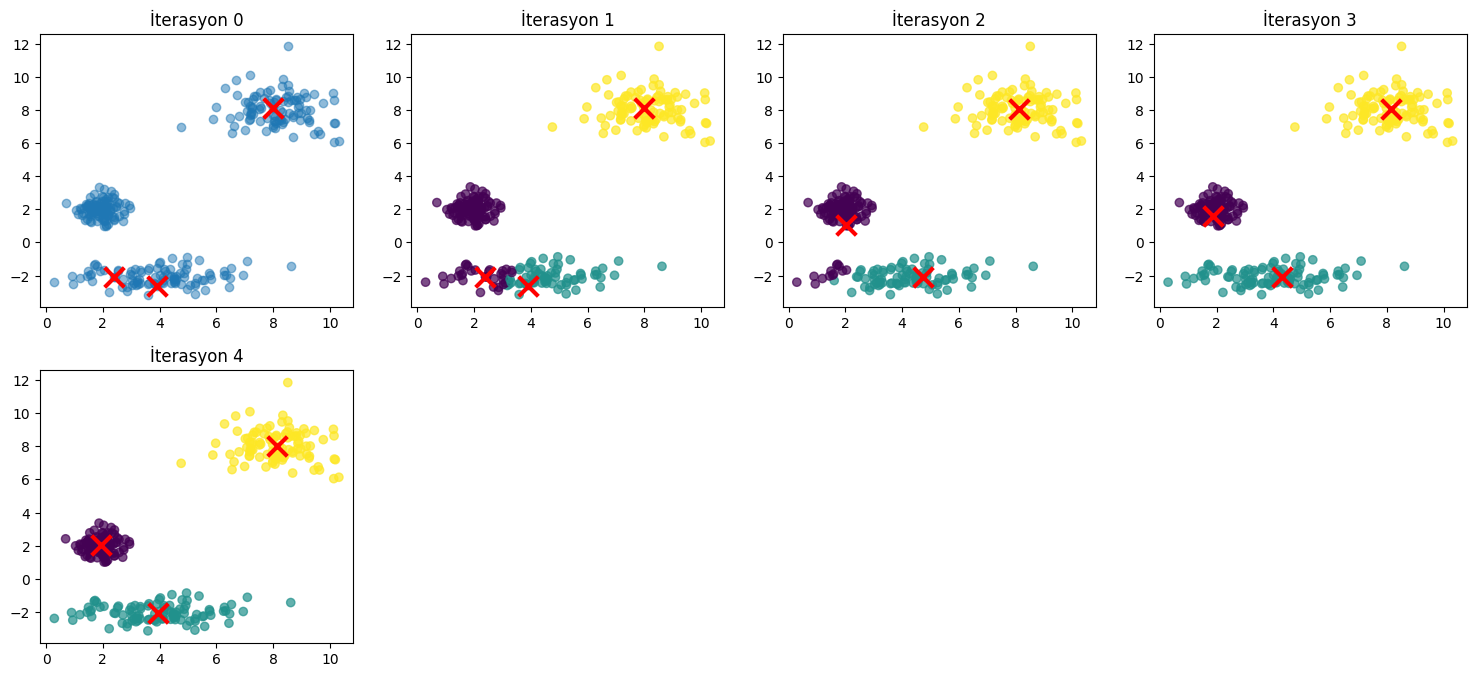


Son İterasyon Detayları:

İterasyon 0:
Küme Merkezleri:
[[ 2.01210282  1.03142448]
 [ 4.73336187 -2.07000807]
 [ 8.12824872  8.04348765]]
Küme Dağılımı: [113  87 100]

İterasyon 1:
Küme Merkezleri:
[[ 1.88312589  1.57042887]
 [ 4.30658568 -2.09276989]
 [ 8.12824872  8.04348765]]
Küme Dağılımı: [100 100 100]

İterasyon 2:
Küme Merkezleri:
[[ 1.94221787  2.01701116]
 [ 3.93244392 -2.06313634]
 [ 8.12824872  8.04348765]]
Küme Dağılımı: [100 100 100]


In [9]:
import numpy as np
import matplotlib.pyplot as plt

class DetailedKMeans:
    def __init__(self, k=3, max_iterations=10, random_state=42):
        self.k = k
        self.max_iterations = max_iterations
        np.random.seed(random_state)
        
        # İterasyon adımlarını kaydetmek için liste
        self.iteration_steps = []
    
    def initialize_centroids(self, X):
        """Rastgele merkez noktaları seç"""
        return X[np.random.choice(X.shape[0], self.k, replace=False)]
    
    def calculate_distances(self, X, centroids):
        """Noktalar ve merkezler arası mesafeleri hesapla"""
        return np.sqrt(((X[:, np.newaxis] - centroids) ** 2).sum(axis=2))
    
    def assign_clusters(self, X, centroids):
        """Her noktayı en yakın merkeze ata"""
        distances = self.calculate_distances(X, centroids)
        return np.argmin(distances, axis=1)
    
    def update_centroids(self, X, labels):
        """Küme merkezlerini güncelle"""
        return np.array([
            X[labels == k].mean(axis=0) 
            for k in range(self.k)
        ])
    
    def fit(self, X):
        """K-Means algoritmasını çalıştır"""
        # Başlangıç merkezlerini seç
        centroids = self.initialize_centroids(X)
        
        # İlk adımı kaydet
        self.iteration_steps.append({
            'centroids': centroids.copy(),
            'labels': None
        })
        
        for iteration in range(self.max_iterations):
            # Küme atamaları
            labels = self.assign_clusters(X, centroids)
            
            # Adımı kaydet
            self.iteration_steps.append({
                'centroids': centroids.copy(),
                'labels': labels.copy()
            })
            
            # Mevcut merkezleri kaydet
            prev_centroids = centroids.copy()
            
            # Merkezleri güncelle
            centroids = self.update_centroids(X, labels)
            
            # Yakınsama kontrolü
            if np.allclose(centroids, prev_centroids, atol=1e-4):
                break
        
        return labels, centroids

# Veri seti oluşturma
def create_dataset():
    np.random.seed(42)
    
    # 3 farklı kümeden oluşan veri seti
    cluster1 = np.random.normal(loc=[2, 2], scale=[0.5, 0.5], size=(100, 2))
    cluster2 = np.random.normal(loc=[8, 8], scale=[1, 1], size=(100, 2))
    cluster3 = np.random.normal(loc=[4, -2], scale=[1.5, 0.5], size=(100, 2))
    
    return np.vstack((cluster1, cluster2, cluster3))

# Veriyi oluştur
X = create_dataset()

# K-Means algoritmasını çalıştır
kmeans = DetailedKMeans(k=3, max_iterations=10)
labels, centroids = kmeans.fit(X)

# Tüm iterasyonları görselleştir
plt.figure(figsize=(15, 10))

# Her iterasyonu ayrı bir alt grafikte göster
for i, step in enumerate(kmeans.iteration_steps):
    plt.subplot(3, 4, i+1)
    
    # İlk iterasyonda sadece noktaları göster
    if step['labels'] is None:
        plt.scatter(X[:, 0], X[:, 1], alpha=0.5)
        plt.title(f'Başlangıç')
    else:
        # Noktalara küme renklerini ver
        plt.scatter(X[:, 0], X[:, 1], c=step['labels'], cmap='viridis', alpha=0.7)
    
    # Merkez noktalarını kırmızı X ile göster
    plt.scatter(step['centroids'][:, 0], step['centroids'][:, 1], 
                c='red', marker='x', s=200, linewidths=3)
    
    plt.title(f'İterasyon {i}')

plt.tight_layout()
plt.show()

# Son iterasyonların detaylarını yazdır
print("\nSon İterasyon Detayları:")
for i, step in enumerate(kmeans.iteration_steps[-3:]):
    print(f"\nİterasyon {i}:")
    print("Küme Merkezleri:")
    print(step['centroids'])
    if step['labels'] is not None:
        print("Küme Dağılımı:", np.bincount(step['labels']))